<sub>**The Annotated ML Handbook** · Part V: scikit-learn</sub>

# Chapter 22: Classification: predicting categories

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/22-sklearn-classification.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 22.1 The data and a first model · *Beginner*

**Load, split, fit**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer(as_frame=True)
X = data.data
y = 1 - data.target
print(X.shape, "| malignant share:", round(y.mean(), 3))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_tr, y_tr)
y_pred = clf.predict(X_te)
y_prob = clf.predict_proba(X_te)[:, 1]
print("accuracy:", round(clf.score(X_te, y_te), 4))
print("first five probabilities:", y_prob[:5].round(3))

(569, 30) | malignant share: 0.373
accuracy: 0.986
first five probabilities: [1.    0.016 0.026 0.009 0.248]


## 22.2 The confusion matrix and the metrics built from it · *Beginner*

**Compute them all**

In [3]:
from sklearn.metrics import (confusion_matrix, classification_report, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, balanced_accuracy_score,
                             matthews_corrcoef)

tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"precision={precision_score(y_te, y_pred):.3f}  recall={recall_score(y_te, y_pred):.3f}  "
      f"F1={f1_score(y_te, y_pred):.3f}  specificity={tn / (tn + fp):.3f}")
print(f"ROC AUC={roc_auc_score(y_te, y_prob):.4f}  PR AUC={average_precision_score(y_te, y_prob):.4f}")
print(f"balanced acc={balanced_accuracy_score(y_te, y_pred):.3f}  MCC={matthews_corrcoef(y_te, y_pred):.3f}")
print(classification_report(y_te, y_pred, target_names=["benign", "malignant"], digits=3))

TN=90 FP=0 FN=2 TP=51
precision=1.000  recall=0.962  F1=0.981  specificity=1.000
ROC AUC=0.9958  PR AUC=0.9940
balanced acc=0.981  MCC=0.970
              precision    recall  f1-score   support

      benign      0.978     1.000     0.989        90
   malignant      1.000     0.962     0.981        53

    accuracy                          0.986       143
   macro avg      0.989     0.981     0.985       143
weighted avg      0.986     0.986     0.986       143



## 22.3 Visual evaluation: confusion matrix, ROC and PR curves · *Intermediate*

**The three standard plots**

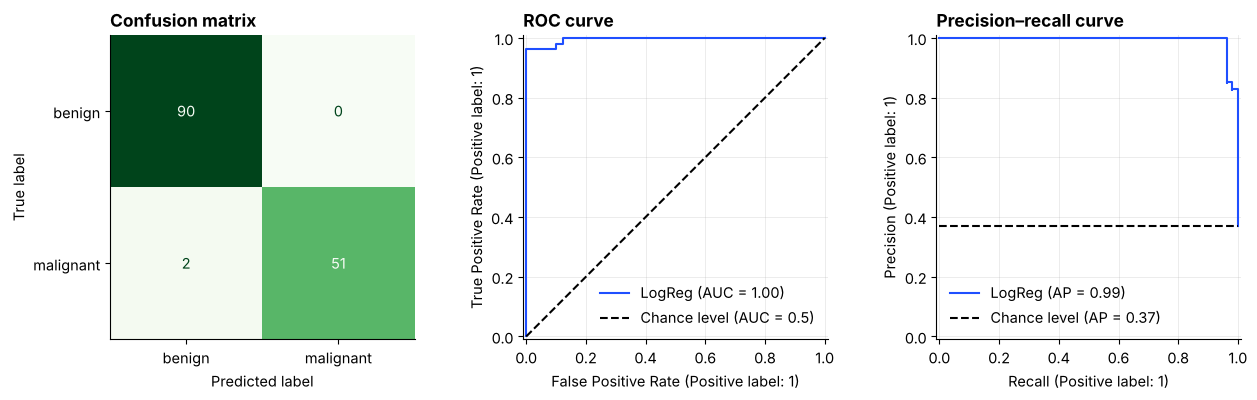

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=["benign", "malignant"],
                                        cmap="Greens", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_te, y_prob, name="LogReg", ax=axes[1], plot_chance_level=True)
axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_te, y_prob, name="LogReg", ax=axes[2], plot_chance_level=True)
axes[2].set_title("Precision–recall curve")
plt.tight_layout()
plt.show()

## 22.4 Choosing the decision threshold · *Intermediate*

**Precision and recall at different thresholds**

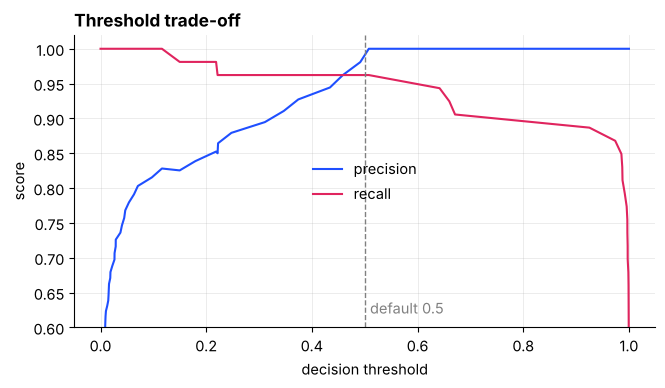

threshold 0.5: recall=0.962 precision=1.000 FN=2
threshold 0.3: recall=0.962 precision=0.895 FN=2
threshold 0.1: recall=1.000 precision=0.828 FN=0


In [5]:
from sklearn.metrics import precision_recall_curve
prec, rec, thr = precision_recall_curve(y_te, y_prob)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
ax.axvline(0.5, color="grey", ls="--", lw=1); ax.text(0.51, 0.62, "default 0.5", color="grey")
ax.set(xlabel="decision threshold", ylabel="score", title="Threshold trade-off", ylim=(0.6, 1.02))
ax.legend()
plt.show()
for t in [0.5, 0.3, 0.1]:
    p = (y_prob >= t).astype(int)
    print(f"threshold {t}: recall={recall_score(y_te, p):.3f} precision={precision_score(y_te, p):.3f} FN={((p == 0) & (y_te == 1)).sum()}")

**Let cross-validation choose the threshold**

In [6]:
from sklearn.model_selection import TunedThresholdClassifierCV

tuned = TunedThresholdClassifierCV(clf, scoring="balanced_accuracy", cv=5)
tuned.fit(X_tr, y_tr)
print("chosen threshold:", round(tuned.best_threshold_, 3))
print("test balanced accuracy:", round(balanced_accuracy_score(y_te, tuned.predict(X_te)), 3))

chosen threshold: 0.566
test balanced accuracy: 0.972


## 22.5 Comparing classifiers · *Intermediate*

**Eight classifiers under the same protocol**

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV

candidates = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "kNN (k=7)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "SVC (RBF)": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(), ensemble=False)),
    "GaussianNB": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(max_depth=4, random_state=0),
    "RandomForest": RandomForestClassifier(n_estimators=400, random_state=0, n_jobs=-1),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=400, random_state=0, n_jobs=-1),
    "HistGradBoost": HistGradientBoostingClassifier(random_state=0),
}
rows = []
for name, model in candidates.items():
    model.fit(X_tr, y_tr)
    prob = model.predict_proba(X_te)[:, 1]
    pred = model.predict(X_te)
    rows.append({"model": name, "accuracy": model.score(X_te, y_te), "recall": recall_score(y_te, pred),
                 "precision": precision_score(y_te, pred, zero_division=0), "ROC_AUC": roc_auc_score(y_te, prob)})
print(pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).round(3).to_string(index=False))

             model  accuracy  recall  precision  ROC_AUC
LogisticRegression     0.986   0.962      1.000    0.996
         SVC (RBF)     0.951   0.943      0.926    0.993
     HistGradBoost     0.979   0.962      0.981    0.993
        ExtraTrees     0.958   0.962      0.927    0.992
      RandomForest     0.958   0.981      0.912    0.987
         kNN (k=7)     0.930   0.925      0.891    0.982
        GaussianNB     0.916   0.906      0.873    0.978
      DecisionTree     0.944   0.981      0.881    0.948
     Dummy (prior)     0.629   0.000      0.000    0.500


## 22.6 Class imbalance · *Intermediate*

**An imbalanced problem: accuracy lies, other metrics don't**

In [8]:
from sklearn.datasets import make_classification

Xi, yi = make_classification(n_samples=4000, n_features=20, n_informative=5,
                             weights=[0.97, 0.03], flip_y=0.01, random_state=1)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, stratify=yi, test_size=0.3, random_state=1)
print("positive share in test:", round(yi_te.mean(), 3))
for name, m in [("dummy", DummyClassifier(strategy="most_frequent")),
                ("logreg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
                ("logreg balanced", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")))]:
    m.fit(Xi_tr, yi_tr)
    p = m.predict(Xi_te)
    print(f"{name:<16} acc={m.score(Xi_te, yi_te):.3f}  recall={recall_score(yi_te, p):.3f}  "
          f"precision={precision_score(yi_te, p, zero_division=0):.3f}  bal_acc={balanced_accuracy_score(yi_te, p):.3f}")

positive share in test: 0.033
dummy            acc=0.967  recall=0.000  precision=0.000  bal_acc=0.500
logreg           acc=0.967  recall=0.000  precision=0.000  bal_acc=0.500
logreg balanced  acc=0.762  recall=0.650  precision=0.088  bal_acc=0.708


## 22.7 Probability calibration · *Advanced*

**Reliability diagram**

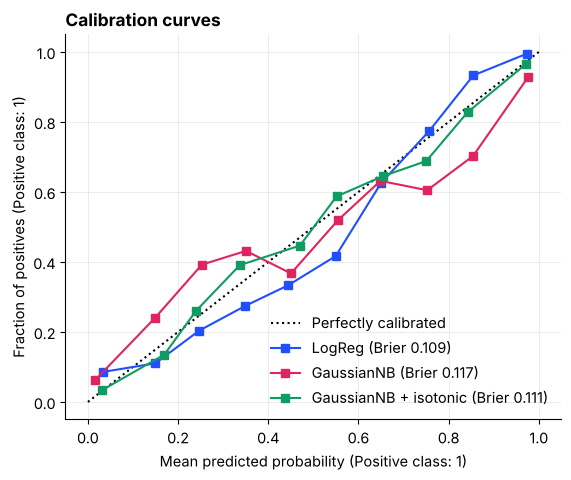

In [9]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

Xc, yc = make_classification(n_samples=6000, n_features=20, n_informative=6, random_state=0)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.5, random_state=0)
fig, ax = plt.subplots(figsize=(6.4, 5))
for name, m in [("LogReg", LogisticRegression(max_iter=1000)), ("GaussianNB", GaussianNB()),
                ("GaussianNB + isotonic", CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5))]:
    m.fit(Xc_tr, yc_tr)
    prob = m.predict_proba(Xc_te)[:, 1]
    CalibrationDisplay.from_predictions(yc_te, prob, n_bins=10, name=f"{name} (Brier {brier_score_loss(yc_te, prob):.3f})", ax=ax)
ax.set_title("Calibration curves")
plt.show()

## 22.8 Multiclass problems · *Intermediate*

**Three wine cultivars**

In [10]:
from sklearn.datasets import load_wine
Xw, yw = load_wine(return_X_y=True)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, stratify=yw, random_state=0)
mc = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xw_tr, yw_tr)
pw = mc.predict(Xw_te)
print(confusion_matrix(yw_te, pw))
print("macro F1:", round(f1_score(yw_te, pw, average="macro"), 3),
      "| weighted F1:", round(f1_score(yw_te, pw, average="weighted"), 3))
print("one-vs-rest ROC AUC:", round(roc_auc_score(yw_te, mc.predict_proba(Xw_te), multi_class="ovr"), 4))

[[15  0  0]
 [ 0 18  0]
 [ 0  0 12]]
macro F1: 1.0 | weighted F1: 1.0
one-vs-rest ROC AUC: 1.0


## Try it yourself

1. Find the threshold that gives at least 98% recall on the training data via cross-validated probabilities (`cross_val_predict(..., method="predict_proba")`) and report test precision at that threshold.
2. Repeat the imbalance experiment with `HistGradientBoostingClassifier(class_weight="balanced")`.
3. Plot ROC curves of three models on one axes by passing the same `ax` to each `RocCurveDisplay`.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 22*.